# HW2: Multiple Object Video Detection
## 1. Data Understanding and Preprocessing
Підключаємо Drive, розпаковуємо дані на локальний диск Colab (швидше за читання з Drive) і дивимось на структуру.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Розпакування:

In [2]:
import os, glob

# Шлях до zip на Drive. Якщо файл лежить у підпапці, поправ шлях.
ZIP_PATH = '/content/drive/MyDrive/multiple-object-video-detection-hw-2-ucu-ai-2026.zip'
DATA_ROOT = '/content/data'

assert os.path.exists(ZIP_PATH), f'Не знайдено: {ZIP_PATH}'

os.makedirs(DATA_ROOT, exist_ok=True)
!unzip -q -o "{ZIP_PATH}" -d "{DATA_ROOT}"

# Подивимось, що розпакувалось
!ls -la {DATA_ROOT}

total 288
drwxr-xr-x 5 root root   4096 Nov  7 15:50 .
drwxr-xr-x 1 root root   4096 Nov  7 15:47 ..
drwxr-xr-x 3 root root   4096 Nov  7 15:47 test
-rw-r--r-- 1 root root 271270 Oct 20 08:34 test_images.csv
drwxr-xr-x 5 root root   4096 Nov  7 15:50 train
drwxr-xr-x 5 root root   4096 Nov  7 15:51 val


Перевірка структури: zip міг розпакуватись у додаткову вкладену папку, тому перевіряємо і за потреби автоматично знаходимо корінь:

In [3]:
# Знаходимо реальний корінь даних (папку, де лежить train/)
for root, dirs, files in os.walk(DATA_ROOT):
    if 'train' in dirs and 'val' in dirs and 'test' in dirs:
        DATA_ROOT = root
        break

print('DATA_ROOT =', DATA_ROOT)
print(sorted(os.listdir(DATA_ROOT)))

for split in ['train', 'val']:
    p = f'{DATA_ROOT}/{split}'
    clips = sorted(os.listdir(f'{p}/images'))
    n_frames = sum(len(os.listdir(f'{p}/images/{c}')) for c in clips)
    n_ignore = len(glob.glob(f'{p}/ignore/*/*.txt'))
    print(f'{split}: {len(clips)} clips, {n_frames} frames, {n_ignore} frames with ignore regions')

test_clips = sorted(os.listdir(f'{DATA_ROOT}/test/images'))
print(f'test: {len(test_clips)} clips')

DATA_ROOT = /content/data
['test', 'test_images.csv', 'train', 'val']
train: 56 clips, 24201 frames, 18090 frames with ignore regions
val: 7 clips, 2846 frames, 1434 frames with ignore regions
test: 48 clips


Ignored regions є у 75% кадрів train і 50% val. Це не рідкісний випадок, тож їх обробка важлива.

Завантаження анотацій у pandas

In [4]:
import json
import pandas as pd
import numpy as np

CLASS_NAMES = ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']

def load_coco(split):
    with open(f'{DATA_ROOT}/{split}/annotations_coco.json') as f:
        coco = json.load(f)
    imgs = pd.DataFrame(coco['images'])
    anns = pd.DataFrame(coco['annotations'])
    return coco, imgs, anns

coco_tr, imgs_tr, anns_tr = load_coco('train')
coco_va, imgs_va, anns_va = load_coco('val')

print('images columns:', imgs_tr.columns.tolist())
print('annotations columns:', anns_tr.columns.tolist())
print('categories:', coco_tr['categories'])
imgs_tr.head(3)

images columns: ['id', 'file_name', 'width', 'height', 'video_id', 'video', 'frame_id']
annotations columns: ['id', 'image_id', 'category_id', 'bbox', 'area', 'iscrowd', 'truncation', 'occlusion', 'track_id', 'orig_category_id', 'ignore']
categories: [{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 'truck'}, {'id': 6, 'name': 'tricycle'}, {'id': 7, 'name': 'bus'}, {'id': 8, 'name': 'motor'}]


,id,file_name,width,height,video_id,video,frame_id
0,1,images/uav0000013_00000_v/0000001.jpg,1344,756,1,uav0000013_00000_v,1
1,2,images/uav0000013_00000_v/0000002.jpg,1344,756,1,uav0000013_00000_v,2
2,3,images/uav0000013_00000_v/0000003.jpg,1344,756,1,uav0000013_00000_v,3


Підготовка єдиної таблиці

In [5]:
def prepare(imgs, anns, split):
    df = anns.merge(imgs[['id', 'video', 'frame_id', 'width', 'height']],
                    left_on='image_id', right_on='id', suffixes=('', '_img'))
    df['split'] = split
    df['x'], df['y'], df['w'], df['h'] = zip(*df['bbox'])
    df['area_px'] = df['w'] * df['h']
    df['is_ignore'] = df['iscrowd'] == 1
    return df

df = pd.concat([prepare(imgs_tr, anns_tr, 'train'),
                prepare(imgs_va, anns_va, 'val')], ignore_index=True)

obj = df[~df.is_ignore].copy()       # реальні об'єкти
ign = df[df.is_ignore].copy()        # ignored regions
obj['cls'] = obj['category_id'] - 1  # 0-based, як у YOLO і submission
obj['cls_name'] = obj['cls'].map(dict(enumerate(CLASS_NAMES)))

print(f'Об\'єктів: {len(obj):,} | ignored regions: {len(ign):,}')
print(obj.groupby('split').size())

Об'єктів: 1,219,648 | ignored regions: 542,704
split
train    1105516
val       114132
dtype: int64


Глянемо на розподіл класів

split,train,val,train_%,val_%
cls_name,,,,
person,328701,50312,29.73,44.08
bicycle,40255,6022,3.64,5.28
car,505301,31821,45.71,27.88
van,46940,6842,4.25,5.99
truck,30498,1359,2.76,1.19
tricycle,41349,5487,3.74,4.81
bus,9653,264,0.87,0.23
motor,102819,12025,9.30,10.54


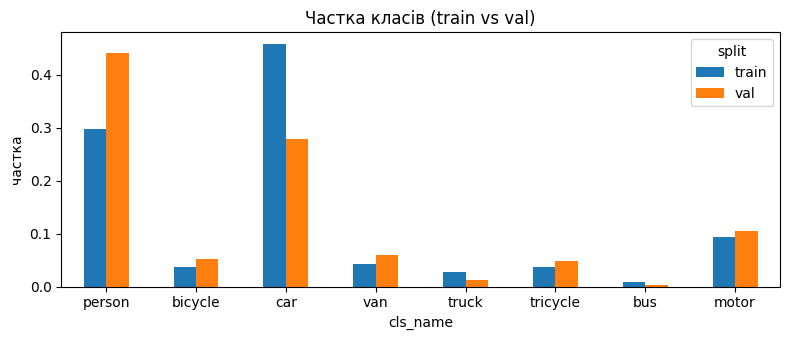

In [16]:
import matplotlib.pyplot as plt

cls_counts = obj.groupby(['cls_name', 'split']).size().unstack(fill_value=0)
cls_counts = cls_counts.reindex(CLASS_NAMES)

cls_stats = cls_counts.copy()

for split in cls_counts.columns:
    cls_stats[f'{split}_%'] = (
        cls_counts[split] / cls_counts[split].sum() * 100
    ).round(2)

display(cls_stats)

(cls_counts / cls_counts.sum()).plot.bar(figsize=(8, 3.5))
plt.title('Частка класів (train vs val)')
plt.ylabel('частка')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Головний висновок, який можемо зробити з цієї діаграми - дисбаланс класів. car (~ 46% у train) і person (~ 30%) домінують. bus менше 1% (9 653 об'єктів у train, лише 264 у val), truck ~2.5%. AP по bus і truck на val буде дуже шумним, тож на це треба зважати при порівнянні моделей.

Також val сильно відрізняється від train за розподілом. person це 44% у val проти 30% у train, а car 28% проти 46%. Бачимо сильну залежність від конкретних кліпів. Це аргумент за те, щоб не покладатися на 7 кліпів val і робити спліт за кліпами з об'єднаного пулу (63 кліпи).

Розміри об'єктів

size
medium    64.1%
small     24.4%
large     11.6%
Name: proportion, dtype: object

Медіана w/h (px): 44.0 / 49.0
               w          h
count  1219648.0  1219648.0
mean        60.9       57.9
std         51.7       36.7
min          4.0        4.0
5%          15.0       21.0
25%         28.0       35.0
50%         44.0       49.0
75%         77.0       71.0
95%        164.0      124.0
max        698.0      758.0


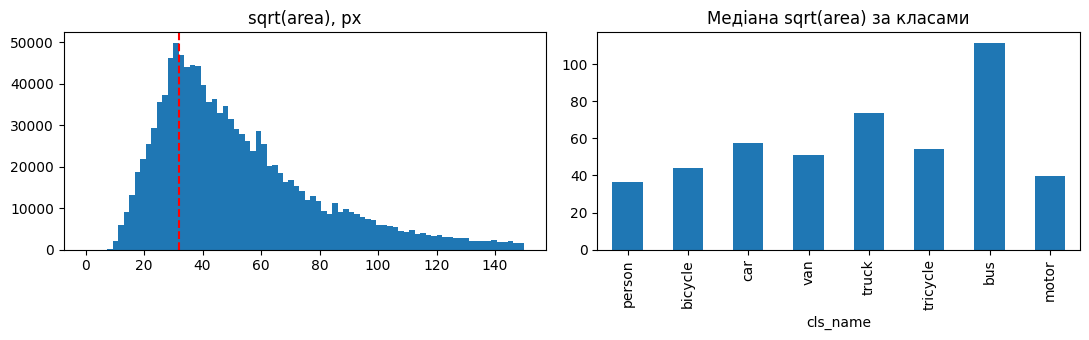

In [7]:
# COCO-категорії за площею: small < 32², medium 32²–96², large > 96²
def size_bucket(a):
    return 'small' if a < 32**2 else ('medium' if a < 96**2 else 'large')

obj['size'] = obj['area_px'].apply(size_bucket)
print((obj['size'].value_counts(normalize=True) * 100).round(1).astype(str) + '%')
print('\nМедіана w/h (px):', obj['w'].median(), '/', obj['h'].median())
print(obj[['w', 'h']].describe(percentiles=[.05, .25, .5, .75, .95]).round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(np.sqrt(obj['area_px']), bins=80, range=(0, 150))
ax[0].set_title('sqrt(area), px'); ax[0].axvline(32, color='r', ls='--')
obj.groupby('cls_name')['area_px'].median().reindex(CLASS_NAMES).pipe(np.sqrt).plot.bar(ax=ax[1])
ax[1].set_title('Медіана sqrt(area) за класами')
plt.tight_layout(); plt.show()

Медіана бокса 44×49 px, small обʼєкти (<32²) складають 24%, medium 64%, large 12%. Але важливо: в нас кліпи від 680×382 до 1920×1080, і при ресайзі 1920→640 об'єкти зменшаться втричі. Тому треба дивитись розміри окремо за роздільністю, бо від цього залежить imgsz і конфігурація anchors.

Щільність сцен і різниця між кліпами:

Об'єктів на кадр:
count    27044.0
mean        45.1
std         31.1
min          1.0
25%         21.0
50%         42.0
75%         57.0
max        180.0
dtype: float64
Кадрів з ≥1 об'єктом: 27044


,n_frames,n_objs,med_sqrt_area,w,h,objs_per_frame
video,,,,,,
uav0000138_00000_v,213,30451,45.4,2688,1512,143.0
uav0000126_00001_v,412,54474,48.4,2688,1512,132.2
uav0000124_00944_v,398,49578,46.3,2688,1512,124.6
uav0000072_04488_v,85,9382,45.8,1904,1071,110.4
uav0000150_02310_v,348,37892,60.0,2688,1512,108.9
uav0000137_00458_v,233,24088,73.2,2688,1512,103.4
uav0000279_00001_v,547,52155,33.4,1904,1071,95.3
uav0000357_00920_v,691,63497,42.8,1904,1071,91.9
uav0000072_06432_v,97,8725,42.3,1904,1071,89.9


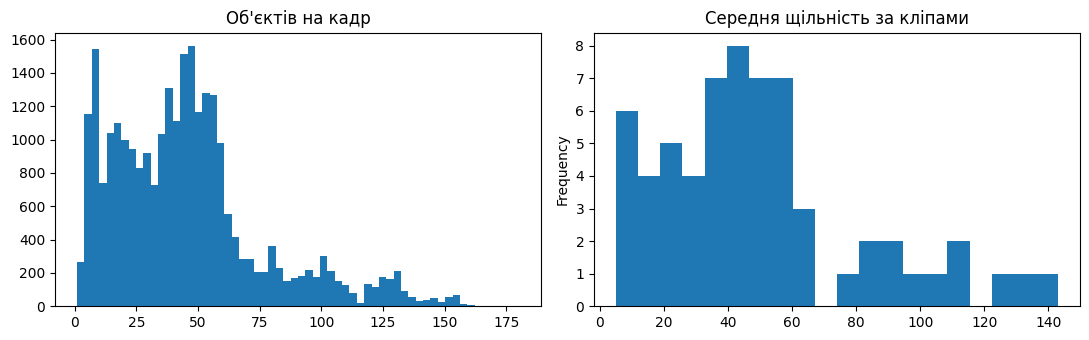

In [11]:
per_frame = obj.groupby(['split', 'image_id']).size()
print('Об\'єктів на кадр:'); print(per_frame.describe().round(1))
print('Кадрів з ≥1 об\'єктом:', len(per_frame))

per_clip = obj.groupby('video').agg(
    n_frames=('image_id', 'nunique'),
    n_objs=('id', 'count'),
    med_sqrt_area=('area_px', lambda a: np.sqrt(a.median())),
    w=('width', 'first'), h=('height', 'first'),
)
per_clip['objs_per_frame'] = per_clip['n_objs'] / per_clip['n_frames']
display(per_clip.sort_values('objs_per_frame', ascending=False).round(1).head(10))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(per_frame, bins=60); ax[0].set_title('Об\'єктів на кадр')
per_clip['objs_per_frame'].plot.hist(bins=20, ax=ax[1]); ax[1].set_title('Середня щільність за кліпами')
plt.tight_layout(); plt.show()

Щільність виявилася такою: 45 об'єктів на кадр, максимум 180.

Давайте для візуальної перевірки GT з YOLO-лейблів намалюємо бокси з YOLO-файлів (ignored regions сірим) на випадкових кадрах:

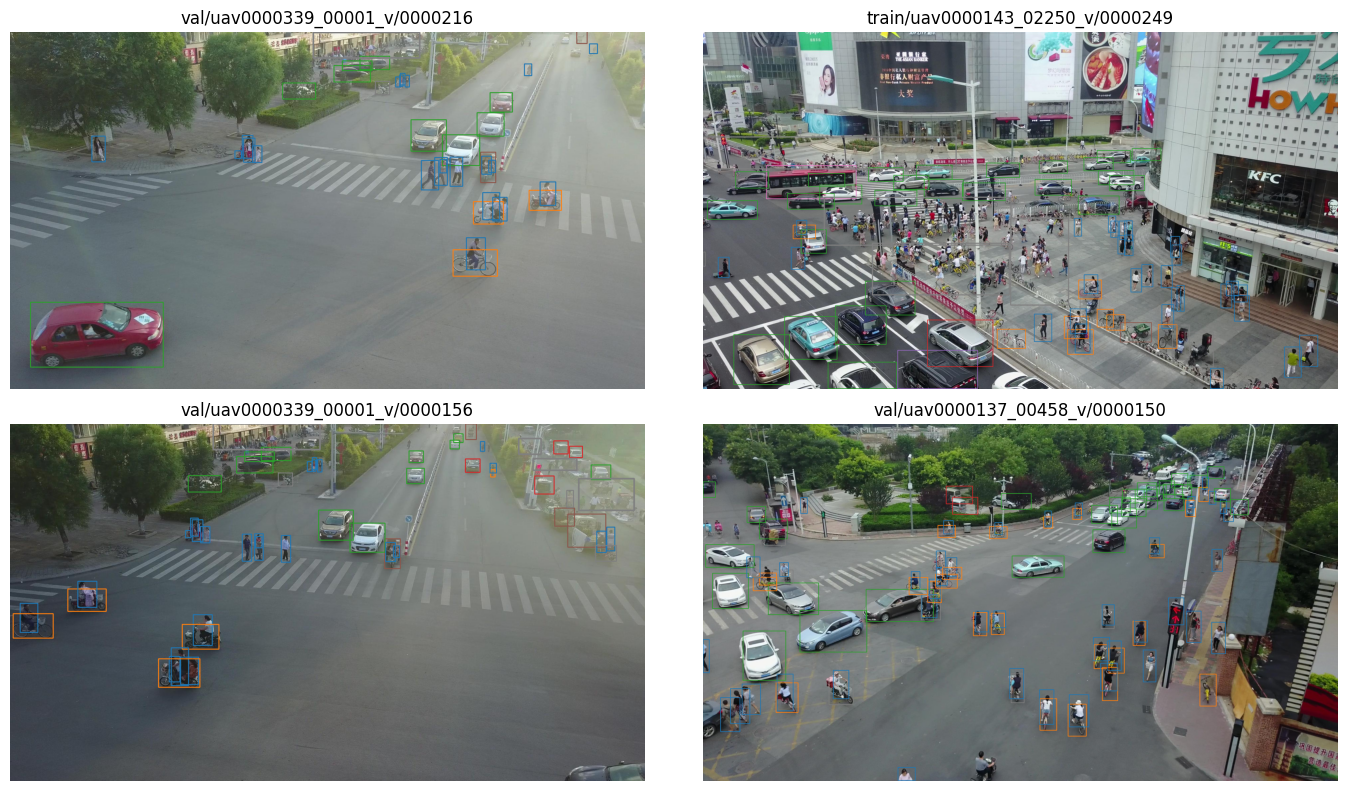

In [9]:
import cv2, random

COLORS = plt.cm.tab10(np.arange(8))[:, :3] * 255

def draw_sample(split, clip, frame):
    img = cv2.cvtColor(cv2.imread(f'{DATA_ROOT}/{split}/images/{clip}/{frame}.jpg'), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lab = f'{DATA_ROOT}/{split}/labels/{clip}/{frame}.txt'
    ig = f'{DATA_ROOT}/{split}/ignore/{clip}/{frame}.txt'
    if os.path.exists(lab):
        for line in open(lab):
            c, cx, cy, w, h = line.split(); c = int(c)
            cx, cy, w, h = float(cx)*W, float(cy)*H, float(w)*W, float(h)*H
            p1, p2 = (int(cx-w/2), int(cy-h/2)), (int(cx+w/2), int(cy+h/2))
            cv2.rectangle(img, p1, p2, COLORS[c].tolist(), 2)
    if os.path.exists(ig):
        for line in open(ig):
            cx, cy, w, h = map(float, line.split())
            cx, cy, w, h = cx*W, cy*H, w*W, h*H
            cv2.rectangle(img, (int(cx-w/2), int(cy-h/2)), (int(cx+w/2), int(cy+h/2)), (128, 128, 128), 3)
    return img

random.seed(0)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax in axes.ravel():
    split = random.choice(['train', 'val'])
    clip = random.choice(sorted(os.listdir(f'{DATA_ROOT}/{split}/images')))
    frame = random.choice(sorted(os.listdir(f'{DATA_ROOT}/{split}/images/{clip}')))[:-4]
    ax.imshow(draw_sample(split, clip, frame)); ax.set_title(f'{split}/{clip}/{frame}'); ax.axis('off')
plt.tight_layout(); plt.show()

Дані виглядять добре: бокси на візуалізації лягають точно на об'єкти, ignored-регіони (сірі) на місці, а у motor/bicycle бачимо вкладений бокс person (водій).

Тепер поглянемо на роздільність і розмір об'єктів:

In [13]:
res = obj.groupby(['width', 'height']).agg(
    clips=('video', 'nunique'), n_objs=('id', 'count'),
    med_w=('w', 'median'), med_h=('h', 'median'),
    small_frac=('size', lambda s: (s == 'small').mean()))
display(res.round(2))

,,clips,n_objs,med_w,med_h,small_frac
width,height,,,,,
1344,756,13,195799,30.0,40.0,0.44
1360,765,1,52919,35.0,29.0,0.51
1904,1071,32,611602,46.0,50.0,0.21
1920,1080,1,40928,39.0,36.0,0.38
2688,1512,12,254883,61.0,57.0,0.14
2720,1530,3,49939,49.0,75.0,0.08
3840,2160,1,13578,59.0,37.0,0.14


І наостанок підготуємо sequence-level фолди: об'єднуємо train+val у пул з 63 кліпів і розбиваємо за кліпами через GroupKFold, щоб кадри одного відео не потрапляли в різні фолди. Також створимо папку hw2 на Drive, в якій будемо зберігати фолди та чекпоінти, бо локальний диск Colab стирається.

In [15]:
from sklearn.model_selection import GroupKFold

clips = obj.groupby('video').size().rename('n_objs').reset_index()
clips['n_frames'] = clips['video'].map(
    pd.concat([imgs_tr, imgs_va]).groupby('video').size())

gkf = GroupKFold(n_splits=5)
clips['fold'] = -1
for k, (_, va_idx) in enumerate(gkf.split(clips, groups=clips['video'])):
    clips.loc[va_idx, 'fold'] = k

# Перевірка: фолди мають бути схожі за розміром, класами і щільністю
chk = obj.merge(clips[['video', 'fold']], on='video')
print(clips.groupby('fold').agg(clips=('video', 'count'), frames=('n_frames', 'sum')))
print((chk.groupby(['fold', 'cls_name']).size().unstack().pipe(lambda d: d.div(d.sum(1), axis=0))
       [CLASS_NAMES] * 100).round(1))

os.makedirs('/content/drive/MyDrive/hw2', exist_ok=True)
clips.to_csv('/content/drive/MyDrive/hw2/folds.csv', index=False)  # зберігаємо, щоб не втратити

      clips  frames
fold               
0        13    5682
1        13    4929
2        13    6408
3        12    5361
4        12    4667
cls_name  person  bicycle   car  van  truck  tricycle  bus  motor
fold                                                             
0           29.6      2.5  48.6  5.2    1.4       4.7  0.5    7.6
1           35.8      3.9  33.3  3.3    6.3       4.4  0.4   12.5
2           35.3      5.2  41.4  3.9    1.2       3.1  0.9    9.1
3           24.4      4.3  49.2  7.2    2.0       3.1  1.1    8.8
4           30.2      2.8  46.9  2.7    2.8       4.2  1.1    9.3


Фолди вийшли збалансованими за кількістю кадрів (4,7–6,4 тис.)

In [19]:
test_df = pd.read_csv(f'{DATA_ROOT}/test_images.csv')

t = test_df.groupby(['width', 'height']).agg(
    clips=('clip', 'nunique'), frames=('image_id', 'count'))
print("Test set:")
display(t)

# Порівняння train+val vs test за роздільністю (за кількістю кадрів)
tv = pd.concat([imgs_tr, imgs_va]).groupby(['width', 'height']).size().rename('frames_trainval')
print("\nTrain+val set:")
display(tv)

Test set:


,,clips,frames
width,height,,
680,382,3,321
960,540,5,279
1344,756,7,441
1360,764,18,1474
1904,1072,4,305
1920,1080,11,991



Train+val set:


,,frames_trainval
width,height,
1344,756,6472
1360,765,962
1904,1071,13354
1920,1080,721
2688,1512,3738
2720,1530,822
3840,2160,978


In [20]:
obj['rel_size'] = np.sqrt(obj['area_px']) / obj[['width', 'height']].max(axis=1)

print('Відносний розмір sqrt(area)/довга_сторона:')
print(obj['rel_size'].describe(percentiles=[.05, .25, .5, .75, .95]).round(4))

# Частка small/tiny після ресайзу довгої сторони до imgsz
for target in [640, 960, 1280, 1536]:
    a = (obj['rel_size'] * target) ** 2
    print(f'imgsz={target}: <32² = {(a < 32**2).mean()*100:.1f}%, '
          f'<16² = {(a < 16**2).mean()*100:.1f}%, <8² = {(a < 8**2).mean()*100:.1f}%')

# Абсолютні кількості за фолдами (для вибору holdout)
chk = obj.merge(clips[['video', 'fold']], on='video')
display(chk.groupby(['fold', 'cls_name']).size().unstack()[CLASS_NAMES])

Відносний розмір sqrt(area)/довга_сторона:
count    1.219648e+06
mean     2.890000e-02
std      1.850000e-02
min      2.900000e-03
5%       1.060000e-02
25%      1.700000e-02
50%      2.390000e-02
75%      3.440000e-02
95%      6.460000e-02
max      3.692000e-01
Name: rel_size, dtype: float64
imgsz=640: <32² = 89.2%, <16² = 53.6%, <8² = 9.7%
imgsz=960: <32² = 73.2%, <16² = 23.5%, <8² = 1.8%
imgsz=1280: <32² = 53.6%, <16² = 9.7%, <8² = 0.6%
imgsz=1536: <32² = 39.4%, <16² = 4.8%, <8² = 0.2%


cls_name,person,bicycle,car,van,truck,tricycle,bus,motor
fold,,,,,,,,
0,63826,5335,104906,11136,3079,10216,1049,16433
1,74006,8154,68878,6861,12988,9099,916,25834
2,101659,14884,119354,11211,3546,8829,2502,26368
3,59682,10485,120135,17483,4881,7495,2585,21519
4,79840,7419,123849,7091,7363,11197,2865,24690


In [21]:
HOLDOUT = 4

# Якщо сесія нова: clips = pd.read_csv('/content/drive/MyDrive/hw2/folds.csv')
# і imgs_tr, imgs_va треба знову завантажити клітинкою 5
allimgs = pd.concat([imgs_tr, imgs_va]).merge(clips[['video', 'fold']], on='video')
allimgs['res'] = allimgs['width'].astype(str) + 'x' + allimgs['height'].astype(str)
display(pd.crosstab(allimgs['fold'], allimgs['res']))

res,1344x756,1360x765,1904x1071,1920x1080,2688x1512,2720x1530,3840x2160
fold,,,,,,,
0,2504,962,1455,0,761,0,0
1,1325,0,2896,0,581,127,0
2,1465,0,4224,0,719,0,0
3,677,0,2626,0,1080,0,978
4,501,0,2153,721,597,695,0


In [22]:
import shutil, cv2
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

OUT = '/content/yolo'
MAX_SIDE = 1280
STEP = 2
MASK_IGNORE = True

os.makedirs(f'{OUT}/images/all', exist_ok=True)
os.makedirs(f'{OUT}/labels/all', exist_ok=True)

# clip -> split (train/val), беремо з диска
clip_split = {c: s for s in ['train', 'val'] for c in os.listdir(f'{DATA_ROOT}/{s}/images')}

jobs = []
for c in sorted(clip_split):
    s = clip_split[c]
    for fn in sorted(os.listdir(f'{DATA_ROOT}/{s}/images/{c}')):
        stem = os.path.splitext(fn)[0]
        if (int(stem) - 1) % STEP == 0:
            jobs.append((s, c, stem))
print(f'Кадрів до конвертації: {len(jobs)} (з {len(clip_split)} кліпів)')

def convert(job):
    s, c, stem = job
    name = f'{c}_{stem}'
    dst_img = f'{OUT}/images/all/{name}.jpg'
    if os.path.exists(dst_img):
        return name
    img = cv2.imread(f'{DATA_ROOT}/{s}/images/{c}/{stem}.jpg')
    H, W = img.shape[:2]
    sc = MAX_SIDE / max(H, W)
    if sc < 1:
        img = cv2.resize(img, (round(W * sc), round(H * sc)), interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]

    ig = f'{DATA_ROOT}/{s}/ignore/{c}/{stem}.txt'
    if MASK_IGNORE and os.path.exists(ig):
        for line in open(ig):
            cx, cy, bw, bh = map(float, line.split())
            x1, x2 = max(0, int((cx - bw / 2) * w)), min(w, int((cx + bw / 2) * w) + 1)
            y1, y2 = max(0, int((cy - bh / 2) * h)), min(h, int((cy + bh / 2) * h) + 1)
            img[y1:y2, x1:x2] = 114

    lab = f'{DATA_ROOT}/{s}/labels/{c}/{stem}.txt'
    shutil.copy(lab, f'{OUT}/labels/all/{name}.txt') if os.path.exists(lab) \
        else open(f'{OUT}/labels/all/{name}.txt', 'w').close()
    cv2.imwrite(dst_img, img, [cv2.IMWRITE_JPEG_QUALITY, 92])
    return name

with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    names = list(tqdm(ex.map(convert, jobs), total=len(jobs), desc='convert', mininterval=5))

# списки зображень для різних експериментів (без копіювання файлів)
fold_of = clips.set_index('video')['fold'].to_dict()
lists = {'train_f4': [], 'val_f4': [], 'all': []}
for (s, c, stem), name in zip(jobs, names):
    p = f'{OUT}/images/all/{name}.jpg'
    lists['all'].append(p)
    lists['val_f4' if fold_of[c] == HOLDOUT else 'train_f4'].append(p)
for k, v in lists.items():
    open(f'{OUT}/{k}.txt', 'w').write('\n'.join(v))
    print(k, len(v))

# YOLO data-конфіги
names_yaml = '\n'.join(f'  {i}: {n}' for i, n in enumerate(CLASS_NAMES))
open(f'{OUT}/data_f4.yaml', 'w').write(f'path: {OUT}\ntrain: {OUT}/train_f4.txt\nval: {OUT}/val_f4.txt\nnames:\n{names_yaml}\n')
open(f'{OUT}/data_all.yaml', 'w').write(f'path: {OUT}\ntrain: {OUT}/all.txt\nval: {OUT}/val_f4.txt\nnames:\n{names_yaml}\n')

Кадрів до конвертації: 13539 (з 63 кліпів)


convert:   0%|          | 0/13539 [00:00<?, ?it/s]

train_f4 11201
val_f4 2338
all 13539


174

In [23]:
!tar -cf /content/drive/MyDrive/hw2/yolo_1280_step2.tar -C /content yolo
!ls -lh /content/drive/MyDrive/hw2/

total 3.3G
-rw------- 1 root root 2.0K Nov  7 16:36 folds.csv
-rw------- 1 root root 3.3G Nov  7 17:29 yolo_1280_step2.tar


In [2]:
# (для нових сесій) Drive змонтовано, тоді:
!tar -xf /content/drive/MyDrive/hw2/yolo_1280_step2.tar -C /content

In [5]:
# (для нових сесій) мінімальні змінні (щоб не повторювати клітинки)
import os, pandas as pd
OUT = '/content/yolo'
CLASS_NAMES = ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']
HOLDOUT = 4
clips = pd.read_csv('/content/drive/MyDrive/hw2/folds.csv')
lists = {k: open(f'{OUT}/{k}.txt').read().split('\n') for k in ['train_f4', 'val_f4', 'all']}
print({k: len(v) for k, v in lists.items()})   # очікувано: 11201, 2338, 13539

{'train_f4': 11201, 'val_f4': 2338, 'all': 13539}


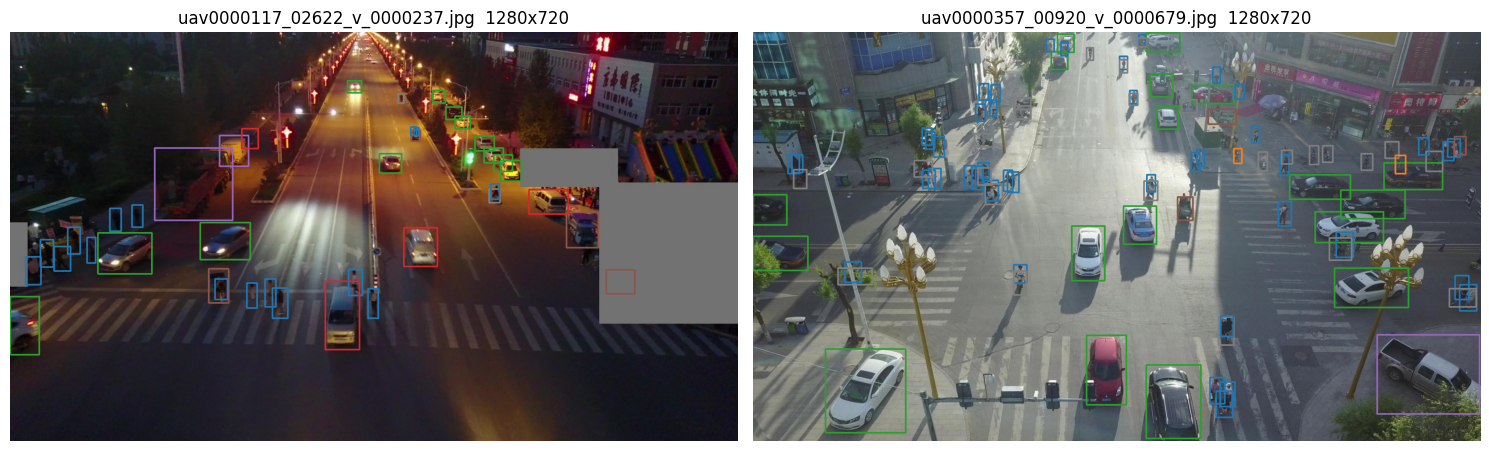

In [24]:
import random
random.seed(1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, p in zip(axes, random.sample(lists['val_f4'], 2)):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
    lab = p.replace('/images/', '/labels/').replace('.jpg', '.txt')
    for line in open(lab):
        c, cx, cy, w, h = line.split(); c = int(c)
        cx, cy, w, h = float(cx)*W, float(cy)*H, float(w)*W, float(h)*H
        cv2.rectangle(img, (int(cx-w/2), int(cy-h/2)), (int(cx+w/2), int(cy+h/2)), COLORS[c].tolist(), 2)
    ax.imshow(img); ax.set_title(f'{os.path.basename(p)}  {W}x{H}'); ax.axis('off')
plt.tight_layout(); plt.show()

Нагадую: сірі прямокутники - це ignored regions, ми їх замалювали сірим, щоб ці регіони для моделі не вважалися фоном.

In [6]:
!pip install -q ultralytics
import os
os.environ['YOLO_VERBOSE'] = 'False'
import torch
print(torch.cuda.get_device_name(0), '| VRAM, GB:', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

Tesla T4 | VRAM, GB: 15.6


In [7]:
from ultralytics import YOLO
from tqdm.auto import tqdm
import time

def attach_progress(model):
    st = {}
    def on_start(tr):
        st['bar'] = tqdm(total=tr.epochs * len(tr.train_loader), desc='train', mininterval=10,
                         bar_format='{l_bar}{bar}| {percentage:3.0f}% [{elapsed}<{remaining}] {postfix}')
        st['t0'] = time.time()
    def on_batch(tr): st['bar'].update(1)
    def on_epoch_end(tr):
        m = tr.metrics
        st['bar'].set_postfix(ep=f'{tr.epoch + 1}/{tr.epochs}',
                              mAP=round(m.get('metrics/mAP50-95(B)', 0), 4))
        st['bar'].write(f"ep {tr.epoch + 1}/{tr.epochs} | mAP50-95={m.get('metrics/mAP50-95(B)', 0):.4f} "
                        f"mAP50={m.get('metrics/mAP50(B)', 0):.4f} | {(time.time() - st['t0']) / 60:.1f} min")
    def on_end(tr): st['bar'].close()
    model.add_callback('on_train_start', on_start)
    model.add_callback('on_train_batch_end', on_batch)
    model.add_callback('on_fit_epoch_end', on_epoch_end)
    model.add_callback('on_train_end', on_end)
    return model

Smoke test (замір швидкості): тренуємо 1 епоху на 10% train, щоб побачити, скільки коштує повна епоха:

In [8]:
t0 = time.time()
model = attach_progress(YOLO('yolo11s.pt'))
model.train(data='/content/yolo/data_f4.yaml', imgsz=960, epochs=1, batch=16, workers=2,
            fraction=0.1, project='/content/drive/MyDrive/hw2/runs', name='smoke',
            exist_ok=True, plots=False, verbose=False, seed=0)
print(f'\n1 епоха на 10% train + повна валідація: {(time.time() - t0) / 60:.1f} хв')

train:   0%|          |   0% [00:00<?] 

ep 1/1 | mAP50-95=0.0111 mAP50=0.0319 | 2.2 min
ep 2/1 | mAP50-95=0.0110 mAP50=0.0318 | 3.6 min

1 епоха на 10% train + повна валідація: 4.1 хв


In [9]:
import os
os.environ['YOLO_VERBOSE'] = 'False'
import time
from ultralytics import YOLO
from tqdm.auto import tqdm

# Піднабори для порівняння моделей: кожен 2-й кадр зі списків (разом step=4 від оригіналу)
train_cmp, val_cmp = lists['train_f4'][::2], lists['val_f4'][::2]
open(f'{OUT}/train_cmp.txt', 'w').write('\n'.join(train_cmp))
open(f'{OUT}/val_cmp.txt', 'w').write('\n'.join(val_cmp))
names_yaml = '\n'.join(f'  {i}: {n}' for i, n in enumerate(CLASS_NAMES))
open(f'{OUT}/data_cmp.yaml', 'w').write(
    f'path: {OUT}\ntrain: {OUT}/train_cmp.txt\nval: {OUT}/val_cmp.txt\nnames:\n{names_yaml}\n')
print('train', len(train_cmp), '| val', len(val_cmp))

def attach_progress(model):
    st = {}
    def on_start(tr):
        st['bar'] = tqdm(total=tr.epochs * len(tr.train_loader), desc='train', mininterval=15,
                         bar_format='{l_bar}{bar}| {percentage:3.0f}% [{elapsed}<{remaining}] {postfix}')
        st['t0'] = time.time()
    def on_batch(tr): st['bar'].update(1)
    def on_epoch_end(tr):
        if tr.epoch + 1 > tr.epochs: return
        m = tr.metrics
        st['bar'].write(f"ep {tr.epoch + 1}/{tr.epochs} | mAP50-95={m.get('metrics/mAP50-95(B)', 0):.4f} "
                        f"mAP50={m.get('metrics/mAP50(B)', 0):.4f} | {(time.time() - st['t0']) / 60:.1f} хв")
    def on_end(tr): st['bar'].close()
    model.add_callback('on_train_start', on_start)
    model.add_callback('on_train_batch_end', on_batch)
    model.add_callback('on_fit_epoch_end', on_epoch_end)
    model.add_callback('on_train_end', on_end)
    return model

RUNS = '/content/drive/MyDrive/hw2/runs'
model = attach_progress(YOLO('yolo11s.pt'))
model.train(data=f'{OUT}/data_cmp.yaml', imgsz=960, epochs=12, batch=16, workers=2,
            close_mosaic=3, max_det=500, seed=0, plots=False, verbose=False,
            project=RUNS, name='yolo11s_base', exist_ok=True)

train 5601 | val 1169


train:   0%|          |   0% [00:00<?] 

ep 1/12 | mAP50-95=0.2071 mAP50=0.3802 | 4.4 хв
ep 2/12 | mAP50-95=0.1894 mAP50=0.3615 | 8.5 хв
ep 3/12 | mAP50-95=0.1690 mAP50=0.3382 | 12.6 хв
ep 4/12 | mAP50-95=0.2060 mAP50=0.3953 | 16.7 хв
ep 5/12 | mAP50-95=0.2039 mAP50=0.3842 | 20.7 хв
ep 6/12 | mAP50-95=0.2009 mAP50=0.3868 | 24.8 хв
ep 7/12 | mAP50-95=0.2099 mAP50=0.3991 | 28.9 хв
ep 8/12 | mAP50-95=0.2097 mAP50=0.4084 | 33.0 хв
ep 9/12 | mAP50-95=0.2084 mAP50=0.4036 | 37.2 хв
ep 10/12 | mAP50-95=0.1959 mAP50=0.3787 | 41.1 хв
ep 11/12 | mAP50-95=0.2011 mAP50=0.3888 | 45.0 хв
ep 12/12 | mAP50-95=0.1973 mAP50=0.3750 | 48.8 хв


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ecd3137d570>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

In [ ]:
# для нової сесії
model = attach_progress(YOLO(f'{RUNS}/yolo11s_base/weights/last.pt'))
model.train(resume=True)

In [10]:
ZIP_PATH = '/content/drive/MyDrive/multiple-object-video-detection-hw-2-ucu-ai-2026.zip'
!unzip -q -o "{ZIP_PATH}" "test/*" "test_images.csv" -d /content/data

In [11]:
import pandas as pd

test_df = pd.read_csv('/content/data/test_images.csv')
paths = ['/content/data/' + f for f in test_df['file_name']]
model = YOLO(f'{RUNS}/yolo11s_base/weights/best.pt')

def make_submission(model, imgsz, out_csv, bs=16):
    rows = {}
    for i in tqdm(range(0, len(paths), bs), desc='predict', mininterval=10):
        res = model.predict(paths[i:i + bs], imgsz=imgsz, conf=0.001, iou=0.6, max_det=500,
                            half=True, verbose=False)
        for p, r in zip(paths[i:i + bs], res):
            b = r.boxes
            xyxy, sc, cl = b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)
            rows[p] = ' '.join(f'{c} {s:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}'
                               for (x1, y1, x2, y2), s, c in zip(xyxy, sc, cl))
    sub = pd.DataFrame({'image_id': test_df['image_id'],
                        'PredictionString': [rows[p] for p in paths]})
    sub.to_csv(out_csv, index=False)
    return sub

sub = make_submission(model, 960, '/content/submission_yolo11s_base.csv')
print(sub.shape, '| середня кількість боксів на кадр:',
      sub['PredictionString'].str.split().str.len().div(6).mean().round(1))
sub.head(3)

predict:   0%|          | 0/239 [00:00<?, ?it/s]

(3811, 2) | середня кількість боксів на кадр: 334.9


,image_id,PredictionString
0,clip_001_0000001,0 0.7534 631.5 919.0 64.0 161.0 0 0.7432 777.5...
1,clip_001_0000002,0 0.7324 624.0 926.0 66.0 154.0 0 0.7266 718.0...
2,clip_001_0000003,0 0.7485 767.5 898.0 72.0 180.0 0 0.7407 614.0...


YOLO модель показала наступний score: 0.23295, що краще за бейзлайн 0.22163



In [12]:
import json, io, contextlib, time, os
import numpy as np
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

ZIP_PATH = '/content/drive/MyDrive/multiple-object-video-detection-hw-2-ucu-ai-2026.zip'
!unzip -q -o "{ZIP_PATH}" "train/annotations_coco.json" "val/annotations_coco.json" -d /content/data

val_cmp = lists['val_f4'][::2]
val_names = [os.path.basename(p)[:-4] for p in val_cmp]       # 'uav..._v_0000237'

def build_gt(names, out_json='/content/gt_cmp.json'):
    """GT в піксельних координатах оригінальних кадрів; ignore-регіони -> iscrowd=1 для кожного з 8 класів."""
    want = {(n.rsplit('_', 1)[0], int(n.rsplit('_', 1)[1])): n for n in names}
    images, anns = [], []
    for s in ['train', 'val']:
        coco = json.load(open(f'/content/data/{s}/annotations_coco.json'))
        new_id = {}
        for im in coco['images']:
            key = (im['video'], int(os.path.splitext(os.path.basename(im['file_name']))[0]))
            if key in want:
                new_id[im['id']] = len(images) + 1
                images.append({'id': len(images) + 1, 'width': im['width'], 'height': im['height'], 'name': want[key]})
        for a in coco['annotations']:
            if a['image_id'] in new_id:
                x, y, w, h = a['bbox']
                for c in ([a['category_id']] if not a['iscrowd'] else range(1, 9)):
                    anns.append({'id': len(anns) + 1, 'image_id': new_id[a['image_id']], 'category_id': c,
                                 'bbox': [x, y, w, h], 'area': w * h, 'iscrowd': int(a['iscrowd'])})
    assert len(images) == len(names), f'знайдено {len(images)} з {len(names)} кадрів, перевір file_name/frame_id'
    json.dump({'images': images, 'annotations': anns,
               'categories': [{'id': i + 1, 'name': n} for i, n in enumerate(CLASS_NAMES)]}, open(out_json, 'w'))
    return out_json

GT_JSON = build_gt(val_names)

def evaluate(predict_fn, names, tag, bs=16, save_dir='/content/drive/MyDrive/hw2/results'):
    """predict_fn(paths) -> список (xyxy, scores, cls 0-based) у пікселях ресайзнутого кадра (довга сторона <=1280)."""
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(GT_JSON)
    by_name = {im['name']: im for im in gt.dataset['images']}
    dets, t_pred = [], 0.0
    for i in tqdm(range(0, len(names), bs), desc=f'eval {tag}', mininterval=10):
        batch = names[i:i + bs]
        t0 = time.time()
        outs = predict_fn([f'{OUT}/images/all/{n}.jpg' for n in batch])
        t_pred += time.time() - t0
        for n, (xyxy, sc, cl) in zip(batch, outs):
            im = by_name[n]
            k = max(im['width'], im['height']) / min(max(im['width'], im['height']), 1280)   # назад в оригінальні пікселі
            for (x1, y1, x2, y2), s, c in zip(xyxy * k, sc, cl):
                dets.append({'image_id': im['id'], 'category_id': int(c) + 1,
                             'bbox': [float(x1), float(y1), float(x2 - x1), float(y2 - y1)], 'score': float(s)})
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(dets), 'bbox')
        E.params.maxDets = [1, 10, 500]
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    P = E.eval['precision'][:, :, :, 0, 2]                      # [IoU, recall, class]
    per_cls = {n: float(P[:, :, k][P[:, :, k] > -1].mean()) for k, n in enumerate(CLASS_NAMES)}
    res = dict(tag=tag, mAP=s[0], AP50=s[1], AP75=s[2], APs=s[3], APm=s[4], APl=s[5],
               ms_per_img=1000 * t_pred / len(names), per_class=per_cls)
    os.makedirs(save_dir, exist_ok=True)
    json.dump(res, open(f'{save_dir}/{tag}.json', 'w'), indent=1)
    print(f"{tag}: mAP={s[0]:.3f} AP50={s[1]:.3f} AP75={s[2]:.3f} | APs={s[3]:.3f} APm={s[4]:.3f} APl={s[5]:.3f} "
          f"| {res['ms_per_img']:.0f} мс/кадр")
    print('по класах:', {k: round(v, 3) for k, v in per_cls.items()})
    return res

def yolo_predict_fn(model, imgsz, conf=0.001, iou=0.6):
    def fn(paths):
        out = []
        for r in model.predict(paths, imgsz=imgsz, conf=conf, iou=iou, max_det=500, half=True, verbose=False):
            b = r.boxes
            out.append((b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)))
        return out
    return fn

from ultralytics import YOLO
RUNS = '/content/drive/MyDrive/hw2/runs'
yolo_base = YOLO(f'{RUNS}/yolo11s_base/weights/best.pt')
res_yolo_base = evaluate(yolo_predict_fn(yolo_base, 960), val_names, 'yolo11s_base')

eval yolo11s_base:   0%|          | 0/74 [00:00<?, ?it/s]

yolo11s_base: mAP=-1.000 AP50=0.368 AP75=0.189 | APs=0.045 APm=0.162 APl=0.356 | 22 мс/кадр
по класах: {'person': 0.203, 'bicycle': 0.058, 'car': 0.481, 'van': 0.173, 'truck': 0.089, 'tricycle': 0.131, 'bus': 0.377, 'motor': 0.068}


## Two-stage Anchor-based

In [13]:
import torch, math, random, cv2
from torch.utils.data import DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

train_cmp = lists['train_f4'][::2]

class YoloDet(torch.utils.data.Dataset):
    def __init__(self, paths, train):
        lab = lambda p: p.replace('/images/', '/labels/').replace('.jpg', '.txt')
        self.paths = [p for p in paths if os.path.getsize(lab(p)) > 0] if train else paths
        self.train, self.lab = train, lab
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        p = self.paths[i]
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
        L = np.array([l.split() for l in open(self.lab(p))], dtype=np.float32).reshape(-1, 5)
        cx, cy, w, h = L[:, 1] * W, L[:, 2] * H, L[:, 3] * W, L[:, 4] * H
        boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1).astype(np.float32)
        if self.train and random.random() < 0.5:                      # горизонтальний фліп
            img = img[:, ::-1]; boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
        keep = ((boxes[:, 2] - boxes[:, 0]) >= 1) & ((boxes[:, 3] - boxes[:, 1]) >= 1)
        t = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float() / 255
        return t, {'boxes': torch.from_numpy(boxes[keep]), 'labels': torch.from_numpy(L[keep, 0].astype(np.int64) + 1)}

def build_frcnn(**kw):
    m = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1, min_size=540, max_size=960,
                                box_detections_per_img=500, box_score_thresh=0.001, box_nms_thresh=0.6, **kw)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 9)  # 8 класів + фон
    return m

def train_frcnn(tag, epochs=3, bs=4, lr=0.005, **kw):
    dl = DataLoader(YoloDet(train_cmp, True), batch_size=bs, shuffle=True, num_workers=2,
                    collate_fn=lambda b: tuple(zip(*b)), drop_last=True)
    model = build_frcnn(**kw).cuda()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=1e-4)
    total, warm = epochs * len(dl), 200
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda it: min(1, (it + 1) / warm) * 0.5 * (1 + math.cos(math.pi * it / total)))
    scaler = torch.cuda.amp.GradScaler()
    bar = tqdm(total=total, desc=tag, mininterval=15, bar_format='{l_bar}{bar}| {percentage:3.0f}% [{elapsed}<{remaining}] {postfix}')
    t0, run = time.time(), None
    for ep in range(epochs):
        model.train()
        for imgs, tg in dl:
            imgs = [i.cuda(non_blocking=True) for i in imgs]
            tg = [{k: v.cuda() for k, v in t.items()} for t in tg]
            with torch.autocast('cuda', dtype=torch.float16):
                loss = sum(model(imgs, tg).values())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 10); scaler.step(opt); scaler.update(); sched.step()
            run = loss.item() if run is None else 0.98 * run + 0.02 * loss.item()
            bar.update(1); bar.set_postfix(ep=f'{ep + 1}/{epochs}', loss=round(run, 3))
        bar.write(f'ep {ep + 1}/{epochs} | loss {run:.3f} | {(time.time() - t0) / 60:.1f} хв')
        torch.save(model.state_dict(), f'{RUNS}/{tag}.pt')           # чекпоінт на Drive кожну епоху
    bar.close()
    return model

def frcnn_predict_fn(model):
    model.eval()
    @torch.no_grad()
    def fn(paths):
        imgs = [torch.from_numpy(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).cuda() for p in paths]
        with torch.autocast('cuda', dtype=torch.float16):
            outs = model(imgs)
        return [(o['boxes'].float().cpu().numpy(), o['scores'].float().cpu().numpy(), (o['labels'] - 1).cpu().numpy()) for o in outs]
    return fn

del yolo_base; torch.cuda.empty_cache()                               # звільняємо VRAM
frcnn_base = train_frcnn('frcnn_base', epochs=3)
res_frcnn_base = evaluate(frcnn_predict_fn(frcnn_base), val_names, 'frcnn_base')

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 120MB/s]
/tmp/ipykernel_1080/1438636424.py:40: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


frcnn_base:   0%|          |   0% [00:00<?] 

/tmp/ipykernel_1080/1438636424.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  torch.nn.utils.clip_grad_norm_(params, 10); scaler.step(opt); scaler.update(); sched.step()


ep 1/3 | loss 0.883 | 10.5 хв
ep 2/3 | loss 0.770 | 20.9 хв
ep 3/3 | loss 0.710 | 31.3 хв


eval frcnn_base:   0%|          | 0/74 [00:00<?, ?it/s]

frcnn_base: mAP=-1.000 AP50=0.359 AP75=0.172 | APs=0.038 APm=0.134 APl=0.392 | 62 мс/кадр
по класах: {'person': 0.163, 'bicycle': 0.034, 'car': 0.402, 'van': 0.132, 'truck': 0.161, 'tricycle': 0.154, 'bus': 0.33, 'motor': 0.094}


In [14]:
import warnings; warnings.filterwarnings('ignore')
import shutil
RESULTS = '/content/drive/MyDrive/hw2/results'
os.makedirs(RESULTS, exist_ok=True)
shutil.copy(GT_JSON, '/content/drive/MyDrive/hw2/gt_cmp.json')       # GT теж на Drive

def evaluate(predict_fn, names, tag, bs=16, save_dir=RESULTS):
    """predict_fn(paths) -> [(xyxy, scores, cls 0-based)] у пікселях ресайзнутого кадра."""
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(GT_JSON)
    by_name = {im['name']: im for im in gt.dataset['images']}
    dets, t_pred = [], 0.0
    for i in tqdm(range(0, len(names), bs), desc=f'eval {tag}', mininterval=10):
        batch = names[i:i + bs]
        t0 = time.time()
        outs = predict_fn([f'{OUT}/images/all/{n}.jpg' for n in batch])
        t_pred += time.time() - t0
        for n, (xyxy, sc, cl) in zip(batch, outs):
            im = by_name[n]
            k = max(im['width'], im['height']) / min(max(im['width'], im['height']), 1280)
            for (x1, y1, x2, y2), s, c in zip(xyxy * k, sc, cl):
                dets.append([im['id'], int(c) + 1, x1, y1, x2 - x1, y2 - y1, s])
    dets = np.array(dets, dtype=np.float32)
    np.savez_compressed(f'{save_dir}/{tag}_dets.npz', dets=dets)       # для аналізу помилок
    coco_dets = [{'image_id': int(d[0]), 'category_id': int(d[1]), 'bbox': [float(v) for v in d[2:6]],
                  'score': float(d[6])} for d in dets]
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(coco_dets), 'bbox')
        E.params.maxDets = [1, 10, 500]
        E.evaluate(); E.accumulate(); E.summarize()
    P = E.eval['precision'][:, :, :, 0, 2]                             # [IoU, recall, class]
    mAP = float(P[P > -1].mean())                                      # виправлено
    per_cls = {n: float(P[:, :, k][P[:, :, k] > -1].mean()) for k, n in enumerate(CLASS_NAMES)}
    s = E.stats
    res = dict(tag=tag, mAP=mAP, AP50=s[1], AP75=s[2], APs=s[3], APm=s[4], APl=s[5],
               ms_per_img=1000 * t_pred / len(names), per_class=per_cls)
    json.dump(res, open(f'{save_dir}/{tag}.json', 'w'), indent=1)
    print(f"{tag}: mAP={mAP:.3f} AP50={s[1]:.3f} AP75={s[2]:.3f} | APs={s[3]:.3f} APm={s[4]:.3f} "
          f"APl={s[5]:.3f} | {res['ms_per_img']:.0f} мс/кадр")
    return res

# переоцінка обох baseline (YOLO з диска, Faster R-CNN з пам'яті або з чекпоінта)
yolo_base = YOLO(f'{RUNS}/yolo11s_base/weights/best.pt')
r1 = evaluate(yolo_predict_fn(yolo_base, 960), val_names, 'yolo11s_base')
del yolo_base; torch.cuda.empty_cache()
try:
    frcnn_base
except NameError:
    frcnn_base = build_frcnn(); frcnn_base.load_state_dict(torch.load(f'{RUNS}/frcnn_base.pt')); frcnn_base.cuda()
r2 = evaluate(frcnn_predict_fn(frcnn_base), val_names, 'frcnn_base')

eval yolo11s_base:   0%|          | 0/74 [00:00<?, ?it/s]

yolo11s_base: mAP=0.198 AP50=0.368 AP75=0.189 | APs=0.045 APm=0.162 APl=0.356 | 22 мс/кадр


eval frcnn_base:   0%|          | 0/74 [00:00<?, ?it/s]

frcnn_base: mAP=0.184 AP50=0.359 AP75=0.172 | APs=0.038 APm=0.134 APl=0.392 | 62 мс/кадр


In [15]:
SUBS = '/content/drive/MyDrive/hw2/submissions'
os.makedirs(SUBS, exist_ok=True)
ZIP_PATH = '/content/drive/MyDrive/multiple-object-video-detection-hw-2-ucu-ai-2026.zip'
if not os.path.exists('/content/data/test/images'):
    os.system(f'unzip -q -o "{ZIP_PATH}" "test/*" "test_images.csv" -d /content/data')
test_df = pd.read_csv('/content/data/test_images.csv')
test_paths = ['/content/data/' + f for f in test_df['file_name']]

def make_submission_generic(predict_fn, tag, bs=8):
    """Інференс на оригінальних test-кадрах (координати одразу в оригінальних пікселях)."""
    rows = []
    for i in tqdm(range(0, len(test_paths), bs), desc=f'submit {tag}', mininterval=10):
        for xyxy, sc, cl in predict_fn(test_paths[i:i + bs]):
            rows.append(' '.join(f'{c} {s:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}'
                                 for (x1, y1, x2, y2), s, c in zip(xyxy, sc, cl)))
    sub = pd.DataFrame({'image_id': test_df['image_id'], 'PredictionString': rows})
    sub.to_csv(f'{SUBS}/{tag}.csv', index=False)
    print(f'{tag}: {sub.shape}, сер. боксів/кадр = {sub.PredictionString.str.split().str.len().div(6).mean():.0f}'
          f' -> {SUBS}/{tag}.csv')

make_submission_generic(frcnn_predict_fn(frcnn_base), 'frcnn_base')

submit frcnn_base:   0%|          | 0/477 [00:00<?, ?it/s]

frcnn_base: (3811, 2), сер. боксів/кадр = 441 -> /content/drive/MyDrive/hw2/submissions/frcnn_base.csv


Ми отримали score 0.18382

In [16]:
from torchvision.models.detection import roi_heads as RH
from torchvision.models.detection._utils import BoxCoder
from torchvision.ops import generalized_box_iou_loss
import torch.nn.functional as F

_orig_select, _orig_loss = RH.RoIHeads.select_training_samples, RH.fastrcnn_loss
_stash, _coder, GIOU_W = {}, BoxCoder((10.0, 10.0, 5.0, 5.0)), 10.0

def _select(self, proposals, targets):
    out = _orig_select(self, proposals, targets)
    _stash['props'] = torch.cat(out[0])           # той самий порядок, що й labels
    return out

def _giou_loss(class_logits, box_regression, labels, regression_targets):
    labels, regression_targets = torch.cat(labels, 0), torch.cat(regression_targets, 0)
    cls_loss = F.cross_entropy(class_logits, labels)
    pos = torch.where(labels > 0)[0]
    if pos.numel() == 0:
        return cls_loss, box_regression.sum() * 0
    reg = box_regression.reshape(class_logits.shape[0], -1, 4)[pos, labels[pos]].float()
    props = _stash['props'][pos].float()
    pred = _coder.decode_single(reg, props)
    tgt = _coder.decode_single(regression_targets[pos].float(), props)
    return cls_loss, GIOU_W * generalized_box_iou_loss(pred, tgt, reduction='sum') / labels.numel()

def set_giou(on):
    RH.RoIHeads.select_training_samples = _select if on else _orig_select
    RH.fastrcnn_loss = _giou_loss if on else _orig_loss

def run_experiment(tag, giou=False, epochs=3, **kw):
    json.dump({'giou': giou, 'giou_w': GIOU_W, 'epochs': epochs, **kw}, open(f'{RUNS}/{tag}_config.json', 'w'))
    set_giou(giou)
    try:
        return train_frcnn(tag, epochs=epochs, **kw)
    finally:
        set_giou(False)

def load_frcnn(tag):                               # відновлення без перетренування
    cfg = json.load(open(f'{RUNS}/{tag}_config.json'))
    kw = {k: v for k, v in cfg.items() if k not in ('giou', 'giou_w', 'epochs')}
    m = build_frcnn(**kw); m.load_state_dict(torch.load(f'{RUNS}/{tag}.pt')); return m.cuda()

In [17]:
try: del frcnn_base
except NameError: pass
torch.cuda.empty_cache()

TAG = 'frcnn_exp1_rpn_roi'
exp = run_experiment(TAG, rpn_pre_nms_top_n_train=3000, rpn_post_nms_top_n_train=3000,
                     rpn_pre_nms_top_n_test=2000, rpn_post_nms_top_n_test=2000,
                     box_positive_fraction=0.5)
res_exp1 = evaluate(frcnn_predict_fn(exp), val_names, TAG)
make_submission_generic(frcnn_predict_fn(exp), TAG)
del exp; torch.cuda.empty_cache()

frcnn_exp1_rpn_roi:   0%|          |   0% [00:00<?] 

ep 1/3 | loss 1.265 | 10.6 хв
ep 2/3 | loss 1.095 | 21.2 хв
ep 3/3 | loss 1.020 | 31.8 хв


eval frcnn_exp1_rpn_roi:   0%|          | 0/74 [00:00<?, ?it/s]

frcnn_exp1_rpn_roi: mAP=0.184 AP50=0.361 AP75=0.171 | APs=0.038 APm=0.132 APl=0.395 | 73 мс/кадр


submit frcnn_exp1_rpn_roi:   0%|          | 0/477 [00:00<?, ?it/s]

frcnn_exp1_rpn_roi: (3811, 2), сер. боксів/кадр = 500 -> /content/drive/MyDrive/hw2/submissions/frcnn_exp1_rpn_roi.csv


Результат став кращим порівняно з базовою моделю Faster R-CNN - зараз це 0.18609 порівняно з 0.18382

In [18]:
# exp2 = exp1 (RPN/RoI тюнінг) + GIoU loss
cfg1 = json.load(open(f'{RUNS}/frcnn_exp1_rpn_roi_config.json'))
exp1_kw = {k: v for k, v in cfg1.items() if k not in ('giou', 'giou_w', 'epochs')}
print('параметри exp1:', exp1_kw)

TAG = 'frcnn_exp2_rpn_roi_giou'
exp = run_experiment(TAG, giou=True, **exp1_kw)
res_exp2 = evaluate(frcnn_predict_fn(exp), val_names, TAG)
make_submission_generic(frcnn_predict_fn(exp), TAG)
del exp; torch.cuda.empty_cache()

параметри exp1: {'rpn_pre_nms_top_n_train': 3000, 'rpn_post_nms_top_n_train': 3000, 'rpn_pre_nms_top_n_test': 2000, 'rpn_post_nms_top_n_test': 2000, 'box_positive_fraction': 0.5}


frcnn_exp2_rpn_roi_giou:   0%|          |   0% [00:00<?] 

ep 1/3 | loss 1.550 | 10.8 хв
ep 2/3 | loss 1.341 | 21.5 хв
ep 3/3 | loss 1.279 | 32.3 хв


eval frcnn_exp2_rpn_roi_giou:   0%|          | 0/74 [00:00<?, ?it/s]

frcnn_exp2_rpn_roi_giou: mAP=0.183 AP50=0.357 AP75=0.171 | APs=0.040 APm=0.131 APl=0.391 | 72 мс/кадр


submit frcnn_exp2_rpn_roi_giou:   0%|          | 0/477 [00:00<?, ?it/s]

frcnn_exp2_rpn_roi_giou: (3811, 2), сер. боксів/кадр = 500 -> /content/drive/MyDrive/hw2/submissions/frcnn_exp2_rpn_roi_giou.csv


Оцінка стала ще вищою: 0.19015, отже другий експеримент виявився найкращим в цьому блоці.

In [19]:
import glob
rows = [json.load(open(f)) for f in sorted(glob.glob(f'{RESULTS}/*.json'))]
cmp = pd.DataFrame(rows).drop(columns='per_class').set_index('tag').round(3)
cmp

,mAP,AP50,AP75,APs,APm,APl,ms_per_img
tag,,,,,,,
frcnn_base,0.184,0.359,0.172,0.038,0.134,0.392,61.604
frcnn_exp1_rpn_roi,0.184,0.361,0.171,0.038,0.132,0.395,72.859
frcnn_exp2_rpn_roi_giou,0.183,0.357,0.171,0.040,0.131,0.391,72.429
yolo11s_base,0.198,0.368,0.189,0.045,0.162,0.356,21.721


аналіз:   0%|          | 0/1169 [00:00<?, ?it/s]

{'TP': '42,627', 'неточний бокс': '22,487', "фон (хибний об'єкт)": '27,858', 'дублікат': '8,588', 'плутанина класів': '11,242', 'пропущено (FN)': '23,540'}
частка пропущених за розміром: {'small': '63%', 'medium': '30%', 'large': '13%'}


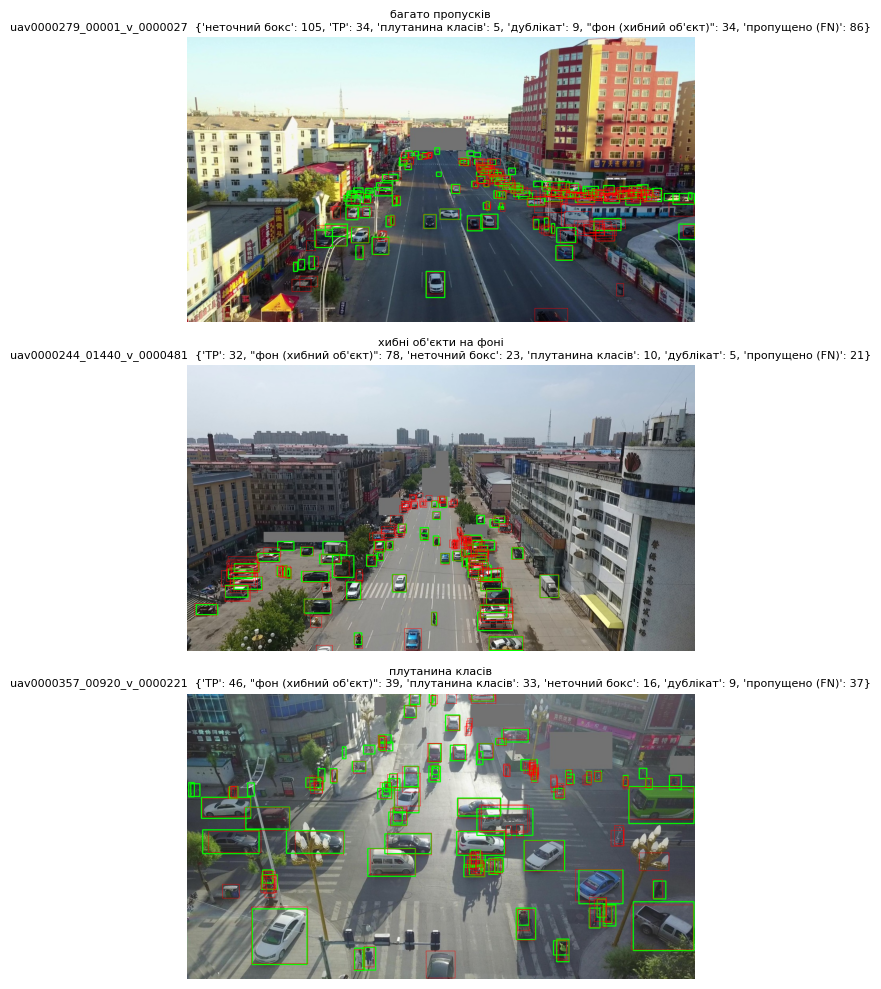

In [23]:
import matplotlib.pyplot as plt
from collections import defaultdict, Counter

TAG, THR = 'frcnn_exp1_rpn_roi', 0.3
with contextlib.redirect_stdout(io.StringIO()):
    gt = COCO(GT_JSON)
imgs = {im['id']: im for im in gt.dataset['images']}
G, D = defaultdict(list), defaultdict(list)
for a in gt.dataset['annotations']: G[a['image_id']].append(a)
for d in np.load(f'{RESULTS}/{TAG}_dets.npz')['dets']:
    if d[6] >= THR: D[int(d[0])].append(d)

def pair_iou(a, b):   # xywh; повертає IoU та ioa (частка площі a усередині b)
    ax1, ay1, ax2, ay2 = a[:, None, 0], a[:, None, 1], a[:, None, 0] + a[:, None, 2], a[:, None, 1] + a[:, None, 3]
    bx1, by1, bx2, by2 = b[None, :, 0], b[None, :, 1], b[None, :, 0] + b[None, :, 2], b[None, :, 1] + b[None, :, 3]
    inter = np.clip(np.minimum(ax2, bx2) - np.maximum(ax1, bx1), 0, None) * np.clip(np.minimum(ay2, by2) - np.maximum(ay1, by1), 0, None)
    aa, ab = (a[:, 2] * a[:, 3])[:, None], (b[:, 2] * b[:, 3])[None, :]
    return inter / (aa + ab - inter + 1e-9), inter / (aa + 1e-9)

bucket = lambda area: 'small' if area < 32**2 else ('medium' if area < 96**2 else 'large')
err_total, per_img = Counter(), {}
fn_size, gt_size = Counter(), Counter()
for iid in tqdm(imgs, desc='аналіз', mininterval=10):
    g = [a for a in G[iid] if not a['iscrowd'] and a['category_id'] == a['category_id']]
    crowd = np.array([a['bbox'] for a in G[iid] if a['iscrowd'] and a['category_id'] == 1], dtype=float).reshape(-1, 4)
    gb = np.array([a['bbox'] for a in g], dtype=float).reshape(-1, 4); gc = np.array([a['category_id'] for a in g])
    dd = sorted(D[iid], key=lambda d: -d[6]); matched = np.zeros(len(g), bool); errs = Counter()
    if dd and len(g):
        db = np.array([d[2:6] for d in dd]); dc = np.array([int(d[1]) for d in dd]); IOU, _ = pair_iou(db, gb)
    if dd and len(crowd): _, IOA = pair_iou(np.array([d[2:6] for d in dd]), crowd)
    for i, d in enumerate(dd):
        if len(g):
            same = (gc == dc[i])
            cand = np.where(same & ~matched, IOU[i], 0)
            if cand.max() >= 0.5: matched[cand.argmax()] = True; errs['TP'] += 1; continue
        if len(crowd) and IOA[i].max() > 0.5: continue                 # у ignore-зоні: не штрафуємо
        if len(g) and IOU[i][~same].max(initial=0) >= 0.5: errs['плутанина класів'] += 1
        elif len(g) and IOU[i][same & matched].max(initial=0) >= 0.5: errs['дублікат'] += 1
        elif len(g) and IOU[i][same].max(initial=0) >= 0.1: errs['неточний бокс'] += 1
        else: errs['фон (хибний об\'єкт)'] += 1
    for a, m in zip(g, matched):
        s = bucket(a['area']); gt_size[s] += 1
        if not m: fn_size[s] += 1; errs['пропущено (FN)'] += 1
    err_total += errs; per_img[iid] = errs

print({k: f'{v:,}' for k, v in err_total.items()})
print('частка пропущених за розміром:', {s: f'{fn_size[s] / gt_size[s]:.0%}' for s in ['small', 'medium', 'large']})

# 3 failure cases: найбільше пропусків / хибних фонових / плутанини класів (серед кадрів з ≥40 GT)
dense = [i for i in imgs if len(G[i]) >= 40]
cases = [('багато пропусків', max(dense, key=lambda i: per_img[i]['пропущено (FN)'])),
         ('хибні об\'єкти на фоні', max(dense, key=lambda i: per_img[i]['фон (хибний об\'єкт)'])),
         ('плутанина класів', max(dense, key=lambda i: per_img[i]['плутанина класів']))]
fig, axes = plt.subplots(3, 1, figsize=(42, 10))
for ax, (title, iid) in zip(axes, cases):
    im = imgs[iid]; k = max(im['width'], im['height']) / min(max(im['width'], im['height']), 1280)
    img = cv2.cvtColor(cv2.imread(f"{OUT}/images/all/{im['name']}.jpg"), cv2.COLOR_BGR2RGB)
    for a in G[iid]:
        if not a['iscrowd']:
            x, y, w, h = [v / k for v in a['bbox']]
            cv2.rectangle(img, (int(x), int(y)), (int(x + w), int(y + h)), (0, 255, 0), 2)     # GT зелений
    for d in D[iid]:
        x, y, w, h = [v / k for v in d[2:6]]
        cv2.rectangle(img, (int(x), int(y)), (int(x + w), int(y + h)), (255, 0, 0), 1)         # передбачення червоні
    ax.imshow(img); ax.axis('off'); ax.set_title(f"{title}\n{im['name']}  {dict(per_img[iid])}", fontsize=8)
plt.tight_layout(); plt.show()

In [24]:
from torchvision.ops import box_iou
model = load_frcnn(TAG); model.eval()
sub = random.Random(0).sample(val_names, 300)
Ns = [100, 300, 1000, 2000]; hit = defaultdict(lambda: np.zeros(len(Ns))); tot = Counter()
with torch.no_grad():
    for n in tqdm(sub, desc='RPN recall', mininterval=10):
        p = f'{OUT}/images/all/{n}.jpg'
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
        t = torch.from_numpy(img).permute(2, 0, 1).float().div(255).cuda()
        il, _ = model.transform([t])
        props = model.rpn(il, model.backbone(il.tensors))[0][0]
        sy, sx = il.image_sizes[0][0] / H, il.image_sizes[0][1] / W
        L = np.array([l.split() for l in open(p.replace('/images/', '/labels/').replace('.jpg', '.txt'))], dtype=np.float32).reshape(-1, 5)
        if not len(L): continue
        gb = torch.tensor(np.stack([(L[:, 1] - L[:, 3] / 2) * W * sx, (L[:, 2] - L[:, 4] / 2) * H * sy,
                                    (L[:, 1] + L[:, 3] / 2) * W * sx, (L[:, 2] + L[:, 4] / 2) * H * sy], 1)).cuda()
        sz = [bucket(((b[2] - b[0]) * (b[3] - b[1])).item()) for b in gb]    # розмір у масштабі входу моделі
        iou = box_iou(gb, props)
        for j, s in enumerate(sz):
            tot[s] += 1
            hit[s] += np.array([(iou[j, :N].max() >= 0.5).item() for N in Ns])
print('recall пропозалів (IoU≥0.5) за розміром, для top-N:', Ns)
for s in ['small', 'medium', 'large']:
    print(f'{s:7s}', (hit[s] / tot[s]).round(2), f'(n={tot[s]})')
del model; torch.cuda.empty_cache()

RPN recall:   0%|          | 0/300 [00:00<?, ?it/s]

recall пропозалів (IoU≥0.5) за розміром, для top-N: [100, 300, 1000, 2000]
small   [       0.49        0.65        0.73        0.73] (n=12887)
medium  [       0.85        0.92        0.98        0.99] (n=3398)
large   [       0.83        0.92        0.96           1] (n=226)


## One-stage Anchor-based

In [25]:
from PIL import Image
from sklearn.cluster import KMeans
from torchvision.models.detection.anchor_utils import AnchorGenerator

# розміри GT у масштабі входу моделі (довга сторона 960)
wh = []
for p in tqdm(train_cmp, desc='розміри GT', mininterval=10):
    W, H = Image.open(p).size
    s = 960 / max(W, H)
    L = np.loadtxt(p.replace('/images/', '/labels/').replace('.jpg', '.txt'), ndmin=2)
    if L.size: wh.append(np.stack([L[:, 3] * W * s, L[:, 4] * H * s], 1))
wh = np.concatenate(wh)

# k-means у лог-просторі sqrt(площі): 15 розмірів = 5 рівнів FPN x 3 масштаби
logsz = np.log(np.sqrt(wh[:, 0] * wh[:, 1])).reshape(-1, 1)
sizes = np.sort(np.exp(KMeans(15, n_init=3, random_state=0).fit(logsz).cluster_centers_.ravel()))
KM_SIZES = tuple(tuple(float(round(s)) for s in sizes[i:i + 3]) for i in range(0, 15, 3))
# співвідношення сторін h/w: 3 кластери
logar = np.log(wh[:, 1] / wh[:, 0]).reshape(-1, 1)
KM_RATIOS = tuple(float(round(r, 2)) for r in
                  np.sort(np.exp(KMeans(3, n_init=3, random_state=0).fit(logar).cluster_centers_.ravel())))
DEF_SIZES = tuple((x, int(x * 2 ** (1 / 3)), int(x * 2 ** (2 / 3))) for x in [32, 64, 128, 256, 512])
print('k-means sizes (P3..P7):', KM_SIZES, '| ratios h/w:', KM_RATIOS)

def best_iou(wh, sizes, ratios):
    """Найкращий IoU між кожним GT і формою якоря (верхня межа, без зсуву центра)."""
    a = np.array([(s / np.sqrt(r), s * np.sqrt(r)) for lv in sizes for s in lv for r in ratios])
    inter = np.minimum(wh[:, None, 0], a[None, :, 0]) * np.minimum(wh[:, None, 1], a[None, :, 1])
    return (inter / (wh[:, None, 0] * wh[:, None, 1] + a[None, :, 0] * a[None, :, 1] - inter)).max(1)

for name, sz, rt in [('стандартні', DEF_SIZES, (0.5, 1.0, 2.0)), ('k-means', KM_SIZES, KM_RATIOS)]:
    b = best_iou(wh, sz, rt)
    print(f'{name:11s}: сер. найкращий IoU={b.mean():.3f} | GT з IoU≥0.5: {(b >= 0.5).mean():.1%} | ≥0.7: {(b >= 0.7).mean():.1%}')

розміри GT:   0%|          | 0/5601 [00:00<?, ?it/s]

k-means sizes (P3..P7): ((6.0, 9.0, 11.0), (14.0, 16.0, 19.0), (22.0, 26.0, 31.0), (37.0, 45.0, 54.0), (67.0, 87.0, 126.0)) | ratios h/w: (0.5, 1.01, 2.03)
стандартні : сер. найкращий IoU=0.522 | GT з IoU≥0.5: 51.7% | ≥0.7: 38.2%
k-means    : сер. найкращий IoU=0.833 | GT з IoU≥0.5: 99.8% | ≥0.7: 96.6%


In [26]:
from functools import partial
from torchvision.models.detection import retinanet_resnet50_fpn, RetinaNet_ResNet50_FPN_Weights
from torchvision.models.detection import retinanet as RN
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

_orig_focal = RN.sigmoid_focal_loss

def build_retina(sizes=None, ratios=(0.5, 1.0, 2.0), **kw):
    extra = {'anchor_generator': AnchorGenerator(sizes, (tuple(ratios),) * len(sizes))} if sizes else {}
    m = retinanet_resnet50_fpn(weights=RetinaNet_ResNet50_FPN_Weights.COCO_V1, min_size=540, max_size=960,
                               detections_per_img=500, score_thresh=0.001, nms_thresh=0.6, **extra, **kw)
    # нова голова класифікації: 8 класів + індекс 0 (не використовується), як у Faster R-CNN
    m.head.classification_head = RetinaNetClassificationHead(256, m.head.classification_head.num_anchors, 9)
    return m

def train_det(tag, builder, epochs=3, bs=4, lr=0.0025):
    dl = DataLoader(YoloDet(train_cmp, True), batch_size=bs, shuffle=True, num_workers=2,
                    collate_fn=lambda b: tuple(zip(*b)), drop_last=True)
    model = builder().cuda()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=1e-4)
    total, warm = epochs * len(dl), 200
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda it: min(1, (it + 1) / warm) * 0.5 * (1 + math.cos(math.pi * it / total)))
    scaler = torch.amp.GradScaler('cuda')
    bar = tqdm(total=total, desc=tag, mininterval=15, bar_format='{l_bar}{bar}| {percentage:3.0f}% [{elapsed}<{remaining}] {postfix}')
    t0, run = time.time(), None
    for ep in range(epochs):
        model.train()
        for imgs, tg in dl:
            imgs = [i.cuda(non_blocking=True) for i in imgs]
            tg = [{k: v.cuda() for k, v in t.items()} for t in tg]
            with torch.autocast('cuda', dtype=torch.float16):
                loss = sum(model(imgs, tg).values())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 10); scaler.step(opt); scaler.update(); sched.step()
            run = loss.item() if run is None else 0.98 * run + 0.02 * loss.item()
            bar.update(1); bar.set_postfix(ep=f'{ep + 1}/{epochs}', loss=round(run, 3))
        bar.write(f'ep {ep + 1}/{epochs} | loss {run:.3f} | {(time.time() - t0) / 60:.1f} хв')
        torch.save(model.state_dict(), f'{RUNS}/{tag}.pt')
    bar.close()
    return model

def run_retina(tag, focal=None, epochs=3, **build):
    json.dump({'focal': focal, 'epochs': epochs, 'build': build}, open(f'{RUNS}/{tag}_config.json', 'w'))
    if focal: RN.sigmoid_focal_loss = partial(_orig_focal, alpha=focal[0], gamma=focal[1])
    try:
        return train_det(tag, lambda: build_retina(**build), epochs=epochs)
    finally:
        RN.sigmoid_focal_loss = _orig_focal

def load_retina(tag):                      # відновлення без перетренування
    b = json.load(open(f'{RUNS}/{tag}_config.json'))['build']
    if b.get('sizes'): b['sizes'] = tuple(tuple(s) for s in b['sizes'])
    m = build_retina(**b); m.load_state_dict(torch.load(f'{RUNS}/{tag}.pt')); return m.cuda()

In [ ]:
torch.cuda.empty_cache()
TAG = 'retina_base'
m = run_retina(TAG)
res_ret_base = evaluate(frcnn_predict_fn(m), val_names, TAG)   # формат виходу такий самий, як у Faster R-CNN
make_submission_generic(frcnn_predict_fn(m), TAG)
del m; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:01<00:00, 105MB/s]


retina_base:   0%|          |   0% [00:00<?] 

ep 1/3 | loss 0.625 | 9.0 хв
ep 2/3 | loss 0.537 | 18.1 хв
ep 3/3 | loss 0.521 | 27.2 хв


eval retina_base:   0%|          | 0/74 [00:00<?, ?it/s]